# Project Title & Domain

## Telecom Churn Prediction & Customer Lifetime Value (CLV) Analysis
**Domain:** Telecommunications, customer analytics and business intelligence.

# Project Overview

This project examines customer records from a telecommunications provider to understand customer churn, identify customer groups associated with higher attrition and estimate a revenue-based Customer Lifetime Value (CLV) proxy. Later stages will use Excel, Python, MySQL and Power BI to support retention reporting.

# Business Problem

Customer churn reduces recurring revenue. Telecom teams need to understand how churn varies with contract types, tenure, service choices and monthly charges. The project will investigate these patterns and produce analysis that supports prioritizing retention efforts.

# Project Objectives

1. Measure the overall churn percentage and compare churn percentages across contract types and internet services.
2. Identify at least three customer characteristics associated with churn, using descriptive statistics and charts.
3. Estimate monthly revenue and average revenue per user (ARPU), stating the assumptions used.
4. Develop a transparent, revenue-based CLV proxy and compare customer segments by their estimated value.
5. In later phases, train and evaluate a churn classification model using precision, recall and F1-score.
6. Present key customer segments and churn KPIs in Power BI in later phases.

# Business Value & Use Case

Intended stakeholders include telecom customer success teams, marketing managers and business analysts. The findings will help them understand churn patterns, assess revenue exposure and identify groups to prioritize for review. The dataset does not demonstrate the effectiveness of any retention intervention.

# Dataset Information

**Dataset:** Telco Customer Churn (IBM sample dataset, distributed on Kaggle).

**Original approval link:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**File:** `data/WA_Fn-UseC_-Telco-Customer-Churn.csv` (CSV)

**Size:** 7,043 rows and 21 columns. Each row represents one customer record.

**Key fields:** `customerID`, `tenure`, `Contract`, `InternetService`, `TechSupport`, `MonthlyCharges`, `TotalCharges`, `Churn`.

**Known initial data-type issue:** `TotalCharges` is read as text and includes 11 blank-string entries. This will be handled in later cleaning stages.

# Planned Analysis

In subsequent phases, inspect data quality and duplicates, convert `TotalCharges` to numeric, document missing-value treatment, explore churn by customer segment, analyse tenure and charges, calculate churn and revenue KPIs, derive a clearly labelled CLV proxy, compare classification algorithms, evaluate model results, use MySQL for reporting queries and build an interactive Power BI dashboard. Proposed charts include churn by contract, churn by internet service, tenure distributions and a customer-value segment chart. No outcomes are assumed in advance.

# Scope & Limitations

This project uses the provided 7,043-row customer-level sample, not live subscriber records. The data does not provide actual retention campaign outcomes, customer acquisition costs, profit margins or verified future customer lifetimes. CLV will therefore be an **estimated revenue proxy**, not observed profit-based lifetime value. The `Churn` label represents churn status in the sample; it does not directly verify a next-month event. Analyses describe patterns and associations, not proven causes.

# Phase 1: Load and Inspect the Approved Dataset
The cells below load the unmodified CSV from a relative path and display basic structural checks. Detailed cleaning, EDA and charts are reserved for later phases.

In [1]:
from pathlib import Path
import pandas as pd

dataset_path = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(dataset_path)
print("Dataset loaded successfully.")

Dataset loaded successfully.


In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Dataset shape (rows, columns):", df.shape)

Dataset shape (rows, columns): (7043, 21)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
print("Data types:\n", df.dtypes)
print("Blank TotalCharges entries:", df["TotalCharges"].astype(str).str.strip().eq("").sum())

Data types:
 customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object
Blank TotalCharges entries: 11


## Initial Observations
The file contains **7,043 rows and 21 columns**, with customer demographic, account, service and billing fields, plus the binary `Churn` field. `TotalCharges` is initially stored as an object/text column rather than a numeric column, and 11 records contain blank strings in this field. These observations guide the planned cleaning work; no transformations are performed in Phase 1.

# Phase 2: Data Preprocessing and Cleaning

## Objective
Assess data quality, handle hidden missing values, standardise data types, encode categorical features, create a scaling demonstration, validate outputs and export datasets. The original CSV remains unchanged.

In [6]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Preserve the original DataFrame
raw_df = df.copy(deep=True)
df_cleaned = df.copy(deep=True)
print("Working copy created:", df_cleaned.shape)

Working copy created: (7043, 21)


## 2.1 Initial quality checks

In [7]:
print("Shape:", df_cleaned.shape)
print("Missing values before conversion:\n", df_cleaned.isna().sum())
print("Duplicate rows:", df_cleaned.duplicated().sum())
print("Duplicate customer IDs:", df_cleaned["customerID"].duplicated().sum())
print("Whitespace-only TotalCharges:", df_cleaned["TotalCharges"].astype(str).str.strip().eq("").sum())
print("Tenure equals zero:", df_cleaned["tenure"].eq(0).sum())

Shape: (7043, 21)
Missing values before conversion:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicate rows: 0
Duplicate customer IDs: 0
Whitespace-only TotalCharges: 11
Tenure equals zero: 11


### Observation
The original `TotalCharges` field is read as text. Eleven entries contain whitespace, which ordinary `isna()` does not detect. The data will be converted to numeric, and zero-tenure customers with blank totals will receive zero total charges, consistent with the project SRS.

## 2.2 Standardise text and repair TotalCharges

In [8]:
# Strip outer spaces from text values while preserving missing values
text_cols = df_cleaned.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    df_cleaned[col] = df_cleaned[col].astype("string").str.strip()

# Replace blank strings with missing values and convert financial field to numeric
df_cleaned["TotalCharges"] = pd.to_numeric(
    df_cleaned["TotalCharges"].replace("", pd.NA), errors="coerce"
)
print("TotalCharges missing after conversion:", df_cleaned["TotalCharges"].isna().sum())
print("Missing TotalCharges for tenure > 0:",
      df_cleaned.loc[df_cleaned["tenure"] > 0, "TotalCharges"].isna().sum())

# Apply zero only where the account tenure is exactly zero
zero_tenure_missing = df_cleaned["TotalCharges"].isna() & df_cleaned["tenure"].eq(0)
df_cleaned.loc[zero_tenure_missing, "TotalCharges"] = 0.0
print("Imputed zero-tenure rows:", zero_tenure_missing.sum())
print("Remaining missing values:\n", df_cleaned.isna().sum()[lambda s: s.gt(0)])

TotalCharges missing after conversion: 11
Missing TotalCharges for tenure > 0: 0
Imputed zero-tenure rows: 11
Remaining missing values:
 Series([], dtype: int64)


## 2.3 Check duplicates, ranges and categories

In [9]:
print("Duplicate customer IDs:", df_cleaned["customerID"].duplicated().sum())
print("Duplicate complete rows:", df_cleaned.duplicated().sum())
print("Negative tenure:", df_cleaned["tenure"].lt(0).sum())
print("Negative MonthlyCharges:", df_cleaned["MonthlyCharges"].lt(0).sum())
print("Negative TotalCharges:", df_cleaned["TotalCharges"].lt(0).sum())
print("\nNumerical summary:\n", df_cleaned[["tenure", "MonthlyCharges", "TotalCharges"]].describe())

for col in ["Contract", "InternetService", "PaymentMethod", "Churn"]:
    print(f"\n{col} categories:\n{df_cleaned[col].value_counts(dropna=False)}")

Duplicate customer IDs: 0
Duplicate complete rows: 0
Negative tenure: 0
Negative MonthlyCharges: 0
Negative TotalCharges: 0

Numerical summary:
             tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000        7043.0
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047    2266.79447
min       0.000000       18.250000           0.0
25%       9.000000       35.500000        398.55
50%      29.000000       70.350000       1394.55
75%      55.000000       89.850000        3786.6
max      72.000000      118.750000        8684.8

Contract categories:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64[pyarrow]

InternetService categories:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64[pyarrow]

PaymentMethod categories:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1

### Quality interpretation
Duplicate customer IDs or unexpected categories would require further review. Do not drop records automatically. Check the meaning of anomalies before changing source records.

## 2.4 Create a cleaned dataset

In [10]:
# Retain original categorical labels for EDA and reporting
assert df_cleaned.shape == (7043, 21), "Unexpected source dimensions"
assert df_cleaned["customerID"].is_unique, "Customer IDs are not unique"
assert df_cleaned["TotalCharges"].notna().all(), "TotalCharges still has missing values"
assert df_cleaned["TotalCharges"].ge(0).all(), "Negative total charges detected"
assert df_cleaned["Churn"].isin(["Yes", "No"]).all(), "Unexpected Churn label"
print("Cleaned data validated:", df_cleaned.shape)
df_cleaned.head()

Cleaned data validated: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2.5 Encode binary categories

In [11]:
# Create independent model-oriented data without modifying reporting dataset
df_encoded = df_cleaned.drop(columns=["customerID"]).copy()

# Map only true Yes/No fields. Three-category service fields are handled separately.
yes_no_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
for col in yes_no_cols:
    df_encoded[col] = df_encoded[col].map({"No": 0, "Yes": 1}).astype("int64")

# Gender is binary in this sample, but is not coded as Yes/No
df_encoded["gender"] = df_encoded["gender"].map({"Female": 0, "Male": 1}).astype("int64")
print("Binary encoded fields:\n", df_encoded[yes_no_cols + ["gender"]].head())

Binary encoded fields:
    Partner  Dependents  PhoneService  PaperlessBilling  Churn  gender
0        1           0             0                 1      0       0
1        0           0             1                 0      0       1
2        0           0             1                 1      1       1
3        0           0             0                 0      0       1
4        0           0             1                 1      1       0


## 2.6 One-hot encode multi-category features

One-hot encoding avoids imposing an artificial numerical order on contract, internet, payment and service categories. For example, `No internet service` is different from `No`.

In [12]:
# Encode remaining categorical fields; keep all categories for traceability
remaining_categorical = df_encoded.select_dtypes(include=["object", "string", "category"]).columns.tolist()
df_encoded = pd.get_dummies(df_encoded, columns=remaining_categorical, dtype=int)
print("Encoded dataset shape:", df_encoded.shape)
print("Remaining text columns:", df_encoded.select_dtypes(include=["object", "string"]).columns.tolist())
assert not df_encoded.isna().any().any(), "Encoded data has missing values"
assert "Churn" in df_encoded.columns, "Target variable missing"

Encoded dataset shape: (7043, 41)
Remaining text columns: []


## 2.7 Standardise numerical features (demonstration)

For Phase 2 practice, standardise tenure and monthly charges in a separate example DataFrame. **Do not use these full-data-fitted scaling values in a future churn model evaluation.** In the modelling phase, split into training and test data first, then fit `StandardScaler` only on the training set.

In [13]:
# Scaling example for data preparation review only
scaled_preview = df_encoded.copy()
scale_cols = ["tenure", "MonthlyCharges"]
scaler_demo = StandardScaler()
scaled_preview[scale_cols] = scaler_demo.fit_transform(scaled_preview[scale_cols])
print("Scaled feature summary (demonstration only):\n", scaled_preview[scale_cols].describe().round(3))

# Keep exported encoded data unscaled to prevent accidental modelling leakage
print("Exported encoded dataset remains unscaled.")

Scaled feature summary (demonstration only):
          tenure  MonthlyCharges
count  7043.000        7043.000
mean     -0.000          -0.000
std       1.000           1.000
min      -1.318          -1.546
25%      -0.952          -0.973
50%      -0.137           0.186
75%       0.921           0.834
max       1.614           1.794
Exported encoded dataset remains unscaled.


## 2.8 Validate and export processed files

In [14]:
from pathlib import Path

# Supports running notebook from the repository root or the scripts/ directory
project_root = Path.cwd()
if not (project_root / "data").exists() and (project_root.parent / "data").exists():
    project_root = project_root.parent
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

cleaned_path = processed_dir / "telco_cleaned.csv"
encoded_path = processed_dir / "telco_encoded.csv"
df_cleaned.to_csv(cleaned_path, index=False)
df_encoded.to_csv(encoded_path, index=False)

# Re-import exported files to confirm files are readable and dimensions are preserved
cleaned_check = pd.read_csv(cleaned_path)
encoded_check = pd.read_csv(encoded_path)
assert cleaned_check.shape == (7043, 21)
assert encoded_check.shape == df_encoded.shape
assert not encoded_check.isna().any().any()
print("Saved:", cleaned_path)
print("Saved:", encoded_path)
print("Cleaned shape:", cleaned_check.shape)
print("Encoded shape:", encoded_check.shape)

Saved: D:\AI-DRIVEN DATA ANALYTICS\Final Project\telecom-churn-clv-analysis\data\processed\telco_cleaned.csv
Saved: D:\AI-DRIVEN DATA ANALYTICS\Final Project\telecom-churn-clv-analysis\data\processed\telco_encoded.csv
Cleaned shape: (7043, 21)
Encoded shape: (7043, 41)


## Phase 2 Summary

- Preserved the original CSV and created a separate working copy.
- Identified whitespace-only values in `TotalCharges`.
- Converted `TotalCharges` to numeric and assigned zero only for missing records with zero tenure.
- Validated duplicate identifiers, numeric ranges and categories.
- Kept categorical labels in a reporting-friendly cleaned dataset.
- Encoded binary and multi-category features in a separate dataset.
- Demonstrated standardisation while documenting future train/test leakage precautions.
- Exported `telco_cleaned.csv` and `telco_encoded.csv` for later phases.

Churn prediction, CLV estimation and dashboards are reserved for later phases.

# Phase 3: Relational Storage and SQL Reporting

This section builds star-schema tables from Phase 2 cleaned data and exports files for MySQL import. MySQL table creation and SQL query execution take place separately in MySQL Workbench.

## 3.1 Inputs and limitations
- Source is the 7,043-row IBM Telco Customer Churn sample.
- Prefer Phase 2's `data/processed/telco_cleaned.csv`. If it is absent, this notebook stops and explains how to create it.
- Preserve `customerID` for relational keys. Model-focused `telco_encoded.csv` is **not** used for human-readable dimensions.
- `Churn` indicates recorded snapshot status. There is no time series, so churn share is **not** a measured monthly churn rate. CLV formulas using future lifespan require assumptions.

In [15]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd()
if not (project_root / 'data').exists() and (project_root.parent / 'data').exists():
    project_root = project_root.parent
cleaned_path = project_root / 'data' / 'processed' / 'telco_cleaned.csv'
if not cleaned_path.exists():
    raise FileNotFoundError(f'Run Phase 2 to create: {cleaned_path}')
df = pd.read_csv(cleaned_path)
print('Loaded:', cleaned_path)
print('Shape:', df.shape)
df.head()

Loaded: D:\AI-DRIVEN DATA ANALYTICS\Final Project\telecom-churn-clv-analysis\data\processed\telco_cleaned.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3.2 Validate the input
Check required columns, unique customer IDs, numeric charges, and complete records before creating dimension tables.

In [16]:
customer_cols = ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents']
service_cols = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
contract_cols = ['Contract', 'PaperlessBilling', 'PaymentMethod']
other_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
required = customer_cols + service_cols + contract_cols + other_cols
assert set(required).issubset(df.columns), 'Required columns missing'
assert df.shape == (7043, 21), 'Unexpected dataset shape'
assert df['customerID'].is_unique, 'customerID must be unique'
assert df[required].notna().all().all(), 'Unexpected missing values'
for col in ['TotalCharges', 'MonthlyCharges', 'tenure']:
    df[col] = pd.to_numeric(df[col], errors='raise')
assert (df[['TotalCharges', 'MonthlyCharges', 'tenure']] >= 0).all().all()
assert set(df['Churn'].unique()) == {'Yes', 'No'}
print('Input validated:', len(df), 'unique customer records')

Input validated: 7043 unique customer records


## 3.3 Build dimension tables
`dim_customer` stores demographic attributes, `dim_services` stores unique service configurations and `dim_contract` stores unique contract/payment configurations. Surrogate integer keys prevent repeated text descriptions in the fact table.

In [17]:
dim_customer = df[customer_cols].rename(columns={
    'customerID': 'customer_id', 'SeniorCitizen': 'senior_citizen',
    'Partner': 'partner', 'Dependents': 'dependents'
}).copy()

dim_services = (df[service_cols].drop_duplicates().sort_values(service_cols)
                .reset_index(drop=True))
dim_services.insert(0, 'service_key', range(1, len(dim_services) + 1))

dim_contract = (df[contract_cols].drop_duplicates().sort_values(contract_cols)
                .reset_index(drop=True))
dim_contract.insert(0, 'contract_key', range(1, len(dim_contract) + 1))

for name, table in [('dim_customer', dim_customer), ('dim_services', dim_services),
                    ('dim_contract', dim_contract)]:
    print(name, table.shape)
dim_services.head()

dim_customer (7043, 5)
dim_services (322, 10)
dim_contract (24, 4)


,service_key,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,1,No,No phone service,DSL,No,No,No,No,No,No
1,2,No,No phone service,DSL,No,No,No,No,No,Yes
2,3,No,No phone service,DSL,No,No,No,No,Yes,No
3,4,No,No phone service,DSL,No,No,No,No,Yes,Yes
4,5,No,No phone service,DSL,No,No,No,Yes,No,No


## 3.4 Build the subscription fact table
Each fact row represents one customer snapshot. Lookup keys are determined by exact matches to the dimension attributes. The dataset provides no event timestamp or separate transactions.

In [18]:
fact_subscriptions = (df[['customerID','tenure','MonthlyCharges','TotalCharges','Churn']
                         + service_cols + contract_cols]
    .merge(dim_services, on=service_cols, how='left', validate='many_to_one')
    .merge(dim_contract, on=contract_cols, how='left', validate='many_to_one'))
fact_subscriptions = fact_subscriptions.rename(columns={
    'customerID':'customer_id', 'MonthlyCharges':'monthly_charges',
    'TotalCharges':'total_charges', 'Churn':'churn'})
fact_subscriptions['churn'] = fact_subscriptions['churn'].map({'Yes':1, 'No':0})
fact_subscriptions = fact_subscriptions[[
    'customer_id','service_key','contract_key','tenure',
    'monthly_charges','total_charges','churn']]
assert fact_subscriptions['churn'].notna().all()
fact_subscriptions['churn'] = fact_subscriptions['churn'].astype(int)
fact_subscriptions.head()

,customer_id,service_key,contract_key,tenure,monthly_charges,total_charges,churn
0,7590-VHVEG,17,7,1,29.85,29.85,0
1,5575-GNVDE,105,12,34,56.95,1889.50,0
2,3668-QPYBK,113,8,2,53.85,108.15,1
3,7795-CFOCW,45,9,45,42.30,1840.75,0
4,9237-HQITU,129,7,2,70.70,151.65,1


## 3.5 Reconciliation and validation
Row counts, primary-key uniqueness and foreign-key coverage must reconcile with the cleaned customer data.

In [19]:
assert len(dim_customer) == 7043
assert len(fact_subscriptions) == 7043
assert dim_customer['customer_id'].is_unique
assert dim_services['service_key'].is_unique
assert dim_contract['contract_key'].is_unique
assert fact_subscriptions['customer_id'].is_unique
assert fact_subscriptions.notna().all().all()
assert fact_subscriptions['service_key'].isin(dim_services['service_key']).all()
assert fact_subscriptions['contract_key'].isin(dim_contract['contract_key']).all()
assert fact_subscriptions['customer_id'].isin(dim_customer['customer_id']).all()
assert abs(df['MonthlyCharges'].sum() - fact_subscriptions['monthly_charges'].sum()) < 1e-6
assert abs(df['TotalCharges'].sum() - fact_subscriptions['total_charges'].sum()) < 1e-6
print('PASS: Row counts, surrogate keys, dimension links and totals reconcile.')

PASS: Row counts, surrogate keys, dimension links and totals reconcile.


## 3.6 Export MySQL import files
Import order: customer, services, contract, then subscriptions. The raw dataset and the cleaned Phase 2 dataset remain unchanged.

In [20]:
warehouse_dir = project_root / 'data' / 'warehouse'
warehouse_dir.mkdir(parents=True, exist_ok=True)
for name, table in [('dim_customer', dim_customer), ('dim_services', dim_services),
                    ('dim_contract', dim_contract), ('fact_subscriptions', fact_subscriptions)]:
    filename = warehouse_dir / f'{name}.csv'
    table.to_csv(filename, index=False)
    print(filename.relative_to(project_root), '-', len(table), 'rows')

data\warehouse\dim_customer.csv - 7043 rows
data\warehouse\dim_services.csv - 322 rows
data\warehouse\dim_contract.csv - 24 rows
data\warehouse\fact_subscriptions.csv - 7043 rows


## 3.7 Preview the SQL reporting metrics using Pandas
The same metrics are defined in `sql/02_reporting_queries.sql`. Their definitions are limited by the sample's snapshot nature.

In [21]:
churn_count = int(fact_subscriptions['churn'].sum())
churn_share = 100 * fact_subscriptions['churn'].mean()
retained = fact_subscriptions.query('churn == 0')
arpu_proxy = retained['monthly_charges'].mean()
print('Total customers:', len(fact_subscriptions))
print('Recorded churn count:', churn_count)
print(f'Recorded churn share: {churn_share:.2f}%')
print(f'Average listed monthly charges for retained customers (ARPU proxy): ${arpu_proxy:.2f}')

Total customers: 7043
Recorded churn count: 1869
Recorded churn share: 26.54%
Average listed monthly charges for retained customers (ARPU proxy): $61.27


## 3.8 Run MySQL (external to this notebook)
1. Install MySQL Server 8.0+ and connect in MySQL Workbench.
2. Run `sql/01_create_star_schema.sql` to create tables and keys.
3. Install loader dependencies: `pip install mysql-connector-python pandas`.
4. Set the `MYSQL_PASSWORD` environment variable and optional `MYSQL_USER`, `MYSQL_HOST`, `MYSQL_PORT`. Never commit credentials.
5. From the project root, run: `python scripts/load_mysql.py`.
6. Run `sql/02_reporting_queries.sql` to check row counts, churn, ARPU proxy, quartiles and joins.

The MySQL import **cannot be claimed completed** until these steps are run successfully in your MySQL environment.

## Phase 3 summary and acceptance criteria
- Four star-schema CSV tables produced with 7,043 customer and fact records.
- All key relationships checked programmatically.
- MySQL DDL has primary/foreign keys and indexes.
- Repeatable loading script and SQL analyses are provided.
- Check database row counts and run queries in MySQL to complete this phase.

**Limitations:** Recorded churn is a sample snapshot label. Actual next-month churn, collected revenue and profit-based CLV are not available. The illustrative 24-month revenue estimate in SQL is a scenario, not observed customer lifetime value.

# Phase 4: Exploratory Data Analysis and Customer Value

The source is a **single customer snapshot**, not longitudinal event data. All churn rates describe recorded group membership, not monthly churn hazards. Results are associations, not causal evidence.

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
charts_dir = project_root / "reports" / "charts"
charts_dir.mkdir(parents=True, exist_ok=True)
eda = df_cleaned.copy()
eda["churn_flag"] = eda["Churn"].map({"No": 0, "Yes": 1})
assert eda["churn_flag"].notna().all()
summary = pd.DataFrame({
    "metric": ["Customers", "Recorded churned customers", "Recorded churn share (%)", "Retained customers", "Listed monthly charges: retained customers ($)", "ARPU proxy: retained monthly charges ($)"],
    "value": [len(eda), int(eda.churn_flag.sum()), round(100*eda.churn_flag.mean(),2), int((eda.churn_flag==0).sum()), round(eda.loc[eda.churn_flag==0,"MonthlyCharges"].sum(),2), round(eda.loc[eda.churn_flag==0,"MonthlyCharges"].mean(),2)]
})
print(summary.to_string(index=False))
summary.to_csv(project_root / "reports" / "executive_kpis.csv", index=False)

                                        metric     value
                                     Customers   7043.00
                    Recorded churned customers   1869.00
                      Recorded churn share (%)     26.54
                            Retained customers   5174.00
Listed monthly charges: retained customers ($) 316985.75
      ARPU proxy: retained monthly charges ($)     61.27


## 4.1 Churn rates by contract, service and payment

Rate denominators are the number of customers within each category. Avoid ranking by churn count alone because group sizes differ.

In [23]:
segment_tables = {}
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen"]:
    t = (eda.groupby(col, dropna=False)["churn_flag"]
         .agg(customers="size", churned="sum", churn_rate="mean").reset_index())
    t["churn_rate_pct"] = (t.pop("churn_rate") * 100).round(2)
    t = t.sort_values("churn_rate_pct", ascending=False)
    segment_tables[col] = t
    t.to_csv(project_root / "reports" / f"churn_by_{col.lower()}.csv", index=False)
    print("\n", col, "\n", t.to_string(index=False))


 Contract 
       Contract  customers  churned  churn_rate_pct
Month-to-month       3875     1655           42.71
      One year       1473      166           11.27
      Two year       1695       48            2.83

 InternetService 
 InternetService  customers  churned  churn_rate_pct
    Fiber optic       3096     1297           41.89
            DSL       2421      459           18.96
             No       1526      113            7.40

 PaymentMethod 
             PaymentMethod  customers  churned  churn_rate_pct
         Electronic check       2365     1071           45.29
             Mailed check       1612      308           19.11
Bank transfer (automatic)       1544      258           16.71
  Credit card (automatic)       1522      232           15.24

 TechSupport 
         TechSupport  customers  churned  churn_rate_pct
                 No       3473     1446           41.64
                Yes       2044      310           15.17
No internet service       1526      113    

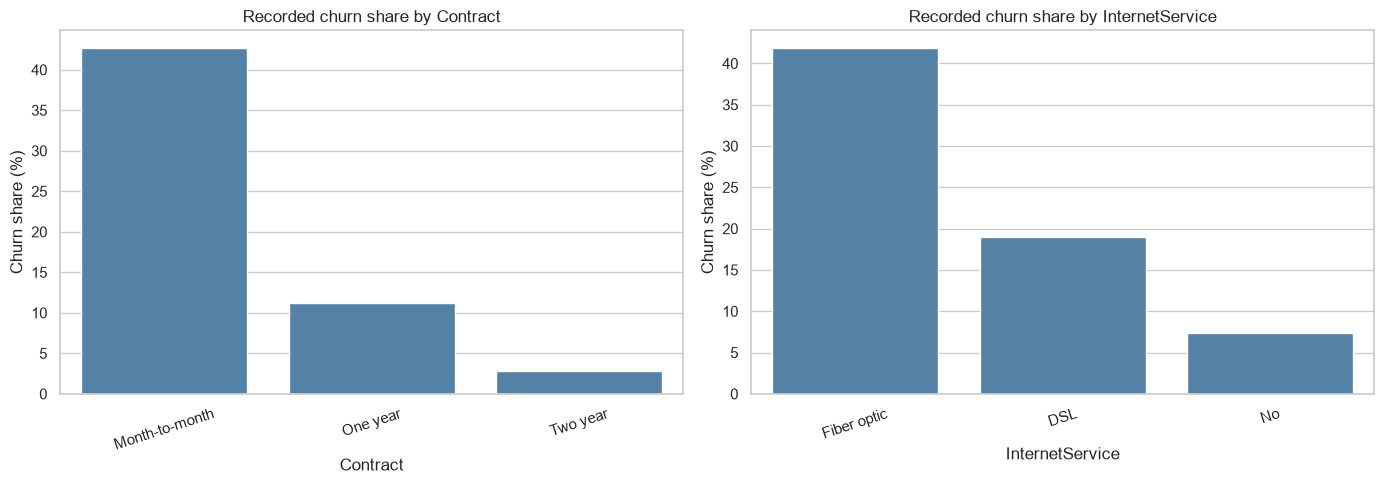

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["Contract", "InternetService"]):
    tab = segment_tables[col]
    sns.barplot(data=tab, x=col, y="churn_rate_pct", ax=ax, color="steelblue")
    ax.set(title=f"Recorded churn share by {col}", ylabel="Churn share (%)", xlabel=col)
    ax.tick_params(axis="x", rotation=18)
plt.tight_layout()
plt.savefig(charts_dir / "churn_by_contract_and_internet.png", dpi=150)
plt.show()

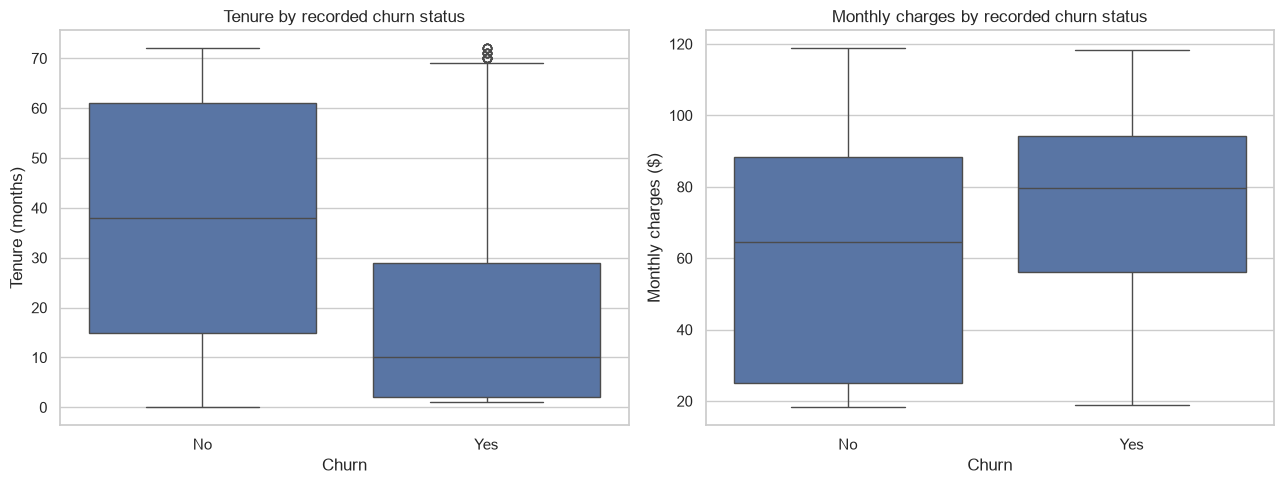

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=eda, x="Churn", y="tenure", ax=axes[0])
axes[0].set(title="Tenure by recorded churn status", ylabel="Tenure (months)")
sns.boxplot(data=eda, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set(title="Monthly charges by recorded churn status", ylabel="Monthly charges ($)")
plt.tight_layout()
plt.savefig(charts_dir / "tenure_and_monthly_charges.png", dpi=150)
plt.show()

## 4.2 Revenue-based customer value proxy

A true profit-based CLV is unavailable. We report a clearly labeled **scenario proxy**: monthly charges multiplied by an assumed 24-month horizon for each retained customer. This is **not a prediction of actual lifetime**, ignores costs and discounting, and should not be interpreted as verified future revenue. We also show the sensitivity at 12 and 36 months. The overall snapshot churn share must not be inverted to estimate monthly customer lifespan.

revenue_segment  customers  average_monthly_charges  average_24m_proxy
         Q1 low       1294                    20.71             496.96
             Q2       1293                    47.27            1134.53
             Q3       1293                    76.58            1837.84
        Q4 high       1294                   100.51            2412.15


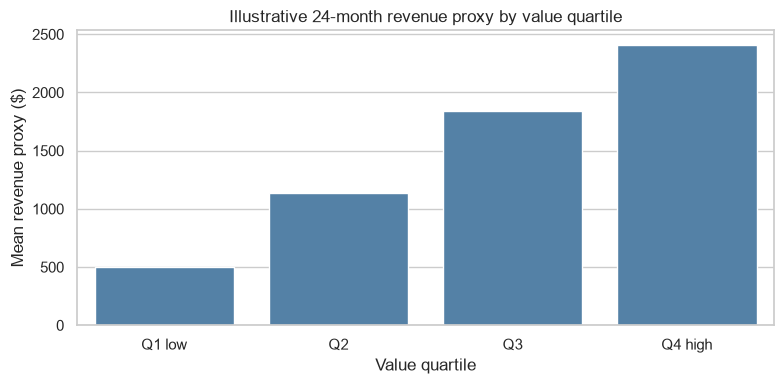

In [26]:
retained = eda.loc[eda["churn_flag"] == 0].copy()
for horizon in [12, 24, 36]:
    retained[f"revenue_proxy_{horizon}m"] = retained["MonthlyCharges"] * horizon
retained["revenue_segment"] = pd.qcut(retained["revenue_proxy_24m"].rank(method="first"), 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
value_summary = (retained.groupby("revenue_segment", observed=True)
    .agg(customers=("customerID", "size"), average_monthly_charges=("MonthlyCharges", "mean"), average_24m_proxy=("revenue_proxy_24m", "mean")).round(2).reset_index())
value_summary.to_csv(project_root / "reports" / "customer_value_segments.csv", index=False)
retained[["customerID", "MonthlyCharges", "revenue_proxy_12m", "revenue_proxy_24m", "revenue_proxy_36m", "revenue_segment"]].to_csv(project_root / "data" / "processed" / "retained_customer_value_proxy.csv", index=False)
print(value_summary.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=value_summary, x="revenue_segment", y="average_24m_proxy", color="steelblue", ax=ax)
ax.set(title="Illustrative 24-month revenue proxy by value quartile", xlabel="Value quartile", ylabel="Mean revenue proxy ($)")
plt.tight_layout()
plt.savefig(charts_dir / "revenue_value_segments.png", dpi=150)
plt.show()

# Phase 5: Churn Classification

The target `Churn` is recorded churn status in the sample. This is a **cross-sectional classification task**, not a validated next-month forecast. Split the data before fitting imputers, encoders or scalers. Do not use `customerID`, `TotalCharges` (potential proxy for tenure and cumulative outcome history), or any derived lifetime-value measure as predictors. Compare a majority-class baseline, Logistic Regression and Random Forest on a held-out stratified test set. The split is random, so results do not demonstrate prospective generalisation.

In [27]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay)
import joblib

model_df = df_cleaned.copy()
y = model_df["Churn"].map({"No": 0, "Yes": 1}).astype(int)
X = model_df.drop(columns=["Churn", "customerID", "TotalCharges"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
num_features = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_features = [c for c in X_train.columns if c not in num_features]
preprocess = ColumnTransformer(transformers=[
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_features),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])
models = {
    "Majority baseline": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=1500, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=250, min_samples_leaf=3, random_state=42, n_jobs=-1),
}
model_results = []
fitted_models = {}
for name, estimator in models.items():
    pipeline = Pipeline([("preprocess", preprocess), ("classifier", estimator)])
    pipeline.fit(X_train, y_train)
    predicted = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    model_results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predicted),
        "precision": precision_score(y_test, predicted, zero_division=0),
        "recall": recall_score(y_test, predicted, zero_division=0),
        "f1": f1_score(y_test, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilities),
    })
    fitted_models[name] = pipeline
results_df = pd.DataFrame(model_results).sort_values("f1", ascending=False)
print(results_df.round(3).to_string(index=False))
results_df.to_csv(project_root / "reports" / "model_comparison.csv", index=False)

              model  accuracy  precision  recall    f1  roc_auc
Logistic regression     0.798      0.638   0.551 0.591    0.839
      Random forest     0.794      0.649   0.489 0.558    0.834
  Majority baseline     0.735      0.000   0.000 0.000    0.500


Training-only cross-validation F1: {'Logistic regression': 0.5937019642973, 'Random forest': 0.561615943755389}
Selected model: Logistic regression
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

Confusion matrix (rows true, columns predicted):
 [[918 117]
 [168 206]]


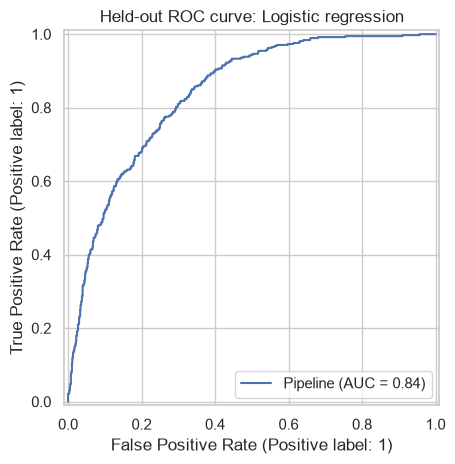

['D:\\AI-DRIVEN DATA ANALYTICS\\Final Project\\telecom-churn-clv-analysis\\models\\churn_classifier.joblib']

In [28]:
# Select a best non-baseline model using *training-only* 3-fold cross validation.
# This avoids selecting a model based on test-set results.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_results = {}
for name in ["Logistic regression", "Random forest"]:
    pipeline = Pipeline([("preprocess", preprocess), ("classifier", models[name])])
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=["f1", "roc_auc"], n_jobs=1)
    cv_results[name] = float(scores["test_f1"].mean())
print("Training-only cross-validation F1:", cv_results)
best_name = max(cv_results, key=cv_results.get)
best_model = fitted_models[best_name]
print("Selected model:", best_name)
print(classification_report(y_test, best_model.predict(X_test), zero_division=0))
print("Confusion matrix (rows true, columns predicted):\n", confusion_matrix(y_test, best_model.predict(X_test)))
RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title("Held-out ROC curve: " + best_name)
plt.tight_layout()
plt.savefig(charts_dir / "model_roc_curve.png", dpi=150)
plt.show()
joblib.dump(best_model, project_root / "models" / "churn_classifier.joblib")

## 5.1 Illustrative retention prioritisation

Export hold-out model probabilities **for evaluation and demonstration only**. Combining estimated 24-month revenue scenario with churn probability provides a *ranking heuristic*, not expected profit or evidence that a retention campaign will work. No customer is contacted; false positives and calibration must be reviewed before operational use.

In [29]:
priority = model_df.loc[X_test.index, ["customerID", "MonthlyCharges", "Contract", "tenure", "Churn"]].copy()
priority["churn_probability"] = best_model.predict_proba(X_test)[:, 1]
priority["revenue_proxy_24m"] = priority["MonthlyCharges"] * 24
priority["priority_score"] = priority["churn_probability"] * priority["revenue_proxy_24m"]
priority = priority.sort_values("priority_score", ascending=False)
priority.to_csv(project_root / "reports" / "holdout_retention_priorities.csv", index=False)
print(priority.head(10).round(2).to_string(index=False))

customerID  MonthlyCharges       Contract  tenure Churn  churn_probability  revenue_proxy_24m  priority_score
1400-MMYXY          105.90 Month-to-month       3   Yes               0.84             2541.6         2143.17
8884-ADFVN          101.95 Month-to-month       7   Yes               0.84             2446.8         2057.99
4587-VVTOX          105.30 Month-to-month       6   Yes               0.81             2527.2         2037.55
6023-YEBUP          100.95 Month-to-month       3   Yes               0.84             2422.8         2031.54
6861-XWTWQ           99.25 Month-to-month       7   Yes               0.85             2382.0         2017.59
5178-LMXOP           95.10 Month-to-month       1   Yes               0.87             2282.4         1983.80
3292-PBZEJ          111.40 Month-to-month      11    No               0.74             2673.6         1981.85
9221-OTIVJ          104.85 Month-to-month      14   Yes               0.79             2516.4         1975.84
2027-FECZV

# Phase 6: Business Intelligence and Final Recommendations

Power BI requirements: import star-schema CSV tables from `data/warehouse/`; join `Fact_Subscriptions[customer_id]` to `Dim_Customer[customer_id]`, `Fact_Subscriptions[service_key]` to `Dim_Services[service_key]`, and `Fact_Subscriptions[contract_key]` to `Dim_Contract[contract_key]` with **many-to-one** relationships. Create churn KPIs, contract/service breakdowns and revenue measures. The included dashboard HTML is a reproducible preview; it is **not a `.pbix` Power BI project**. A `.pbix` still needs to be built and saved in Power BI Desktop.

In [30]:
# Generate a standalone interactive Plotly HTML report from validated results.
import plotly.graph_objects as go
from plotly.subplots import make_subplots
contract = segment_tables["Contract"]
internet = segment_tables["InternetService"]
fig = make_subplots(rows=2, cols=2, subplot_titles=("Recorded churn by contract", "Recorded churn by internet service", "24-month revenue scenario by quartile", "Model comparison: F1"), vertical_spacing=.18, horizontal_spacing=.15)
fig.add_trace(go.Bar(x=contract["Contract"], y=contract["churn_rate_pct"], name="Contract churn %"), row=1, col=1)
fig.add_trace(go.Bar(x=internet["InternetService"], y=internet["churn_rate_pct"], name="Internet churn %"), row=1, col=2)
fig.add_trace(go.Bar(x=value_summary["revenue_segment"].astype(str), y=value_summary["average_24m_proxy"], name="24m proxy ($)"), row=2, col=1)
fig.add_trace(go.Bar(x=results_df["model"], y=results_df["f1"], name="Held-out F1"), row=2, col=2)
fig.update_layout(title=f"Telco customer analytics | {len(eda):,} customers | recorded churn share {100*eda.churn_flag.mean():.1f}%", height=850, showlegend=False, template="plotly_white")
fig.update_yaxes(title_text="Churn share (%)", row=1, col=1)
fig.update_yaxes(title_text="Churn share (%)", row=1, col=2)
fig.update_yaxes(title_text="Mean 24m scenario ($)", row=2, col=1)
fig.update_yaxes(title_text="F1", row=2, col=2)
dashboard_path = project_root / "dashboard" / "telecom_analytics_preview.html"
fig.write_html(dashboard_path, include_plotlyjs=True)
print("Dashboard preview:", dashboard_path)

Dashboard preview: D:\AI-DRIVEN DATA ANALYTICS\Final Project\telecom-churn-clv-analysis\dashboard\telecom_analytics_preview.html


In [31]:
# Final reproducibility audit
assert (project_root / "data" / "processed" / "telco_cleaned.csv").exists()
assert (project_root / "data" / "warehouse" / "fact_subscriptions.csv").exists()
assert (project_root / "models" / "churn_classifier.joblib").exists()
assert (project_root / "dashboard" / "telecom_analytics_preview.html").exists()
assert 0 <= y.mean() <= 1
print("SUCCESS: Phases 1-6 generated cleaned data, warehouse extracts, charts, model, metrics, and HTML dashboard preview.")
print("Pending manual tasks: run MySQL DDL/import and build Power BI .pbix in Desktop.")

SUCCESS: Phases 1-6 generated cleaned data, warehouse extracts, charts, model, metrics, and HTML dashboard preview.
Pending manual tasks: run MySQL DDL/import and build Power BI .pbix in Desktop.
